# Estimate the Causal Impact of an Intervention

In [66]:
import pandas as pd

In [67]:
df = pd.read_csv("data.csv")

In [68]:
df.head()

,state,year,cigsale,lnincome,beer,age15to24,retprice
0,Alabama,1970,89.8,NaN,NaN,0.178862,39.6
1,Alabama,1971,95.4,NaN,NaN,0.179928,42.7
2,Alabama,1972,101.1,9.498476,NaN,0.180994,42.3
3,Alabama,1973,102.9,9.550107,NaN,0.182060,42.1
4,Alabama,1974,108.2,9.537163,NaN,0.183126,43.1


In [69]:
df.shape

(1209, 7)

In [70]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1209 entries, 0 to 1208
Data columns (total 7 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   state      1209 non-null   object 
 1   year       1209 non-null   int64  
 2   cigsale    1209 non-null   float64
 3   lnincome   1014 non-null   float64
 4   beer       546 non-null    float64
 5   age15to24  819 non-null    float64
 6   retprice   1209 non-null   float64
dtypes: float64(5), int64(1), object(1)
memory usage: 66.2+ KB


In [71]:
df.isnull().sum()

state          0
year           0
cigsale        0
lnincome     195
beer         663
age15to24    390
retprice       0
dtype: int64

In [72]:
print(sorted(df["state"].unique()))

['Alabama', 'Arkansas', 'California', 'Colorado', 'Connecticut', 'Delaware', 'Georgia', 'Idaho', 'Illinois', 'Indiana', 'Iowa', 'Kansas', 'Kentucky', 'Louisiana', 'Maine', 'Minnesota', 'Mississippi', 'Missouri', 'Montana', 'Nebraska', 'Nevada', 'New Hampshire', 'New Mexico', 'North Carolina', 'North Dakota', 'Ohio', 'Oklahoma', 'Pennsylvania', 'Rhode Island', 'South Carolina', 'South Dakota', 'Tennessee', 'Texas', 'Utah', 'Vermont', 'Virginia', 'West Virginia', 'Wisconsin', 'Wyoming']


In [73]:
print("There is California:", "California" in df["state"].unique())

There is California: True


In [74]:
df["state"].nunique()

39

In [75]:
print(df["year"].min(), df["year"].max())

1970 2000


In [76]:
print(sorted(df["year"].unique().tolist()))

[1970, 1971, 1972, 1973, 1974, 1975, 1976, 1977, 1978, 1979, 1980, 1981, 1982, 1983, 1984, 1985, 1986, 1987, 1988, 1989, 1990, 1991, 1992, 1993, 1994, 1995, 1996, 1997, 1998, 1999, 2000]


In [77]:
df.groupby("state")["year"].count().value_counts()

year
31    39
Name: count, dtype: int64

In [78]:
df.duplicated().sum()

np.int64(0)

In [79]:
df.duplicated(subset=["state", "year"]).sum()

np.int64(0)

#### 1. About the Data

The dataset is a state-year panel focused on California's Proposition 99: 39 states × 31 years (1970–2000) = 1,209 rows and 7 columns.
- Outcome: "cigsale", per capita cigarette sales (in packs)
- Predictors: "retprice", "lnincome", "beer", "age15to24"
- Treated Unit: California
- Control Group: The other 38 states
- Pre-period: 1970–1988
- Post-period: 1989–2000


#### 2. Data Quality

- The panel is balanced and complete; state-year pairs do not duplicate.
- "cigsale" and "retprice" are fully populated with no missing values.
- There are missing values in the "lnincome" (195), "beer" (663), and "age15to24" (390) columns.
- The number of missing values is perfectly divisible by 39 (the number of states), indicating that the missingness represents completely omitted years across all states.

#### 3. Decision

I chose not to drop the missing values, as doing so would result in losing a significant portion of the pre-intervention period.The synthetic control will be built using the outcome (cigsale) alone, so the missing values in the predictors will not affect the estimate. Adding the predictors is a possible robustness extension. Since the primary outcome variable is fully complete, the core analysis remains unaffected.

-----------------------------------------------------------------------------------------------------------------------------------------------------------
#### 1. Data haqqında

Data Kaliforniya Proposition 99 üzrə ştat-il panelidir: **39 ştat × 31 il (1970-2000) = 1209 sətir, 7 sütun**.

- Outcome: "cigsale", adambaşına siqaret satışı (paket ilə)
- Prediktorlar: "retprice", "lnincome", "beer", "age15to24"
- Treated unit: California
- Nəzarət qrupu: digər 38 ştat
- Pre-period: 1970-1988
- Post-period: 1989-2000

#### 2. Data keyfiyyəti

- Panel tamdır, ştat-il cütləri təkrarlanmır
- "cigsale" və "retprice" tam doldurulub
- "lnincome" (195), "beer" (663) və "age15to24" (390) sütunlarında boş dəyər var
- Boş dəyərlərin sayı 39-a (ştat sayına) bölünür, yəni boşluq müəyyən illərdə bütün ştatlar üçün çatışmayan dəyərlərdən ibarətdir

#### 3. Qərar

Boş dəyərləri silmədim, çünki silmək pre-period-un böyük hissəsini itirərdi. Synthetic control yalnız outcome (cigsale) ilə quruluacaq, ona görə prediktorlardakı boşluqlar nəticəyə təsir etməyəcək. Prediktorları əlavə etmək mümkün robustluq yoxlamasıdır. Outcome tam olduğu üçün əsas analiz təsirlənmir.

## EDA

In [80]:
import matplotlib.pyplot as plt

In [81]:
calf = df[df["state"] == "California"].set_index("year")["cigsale"]
others = df[df["state"] != "California"].groupby("year")["cigsale"].mean()

print(len(calf), len(others))

31 31


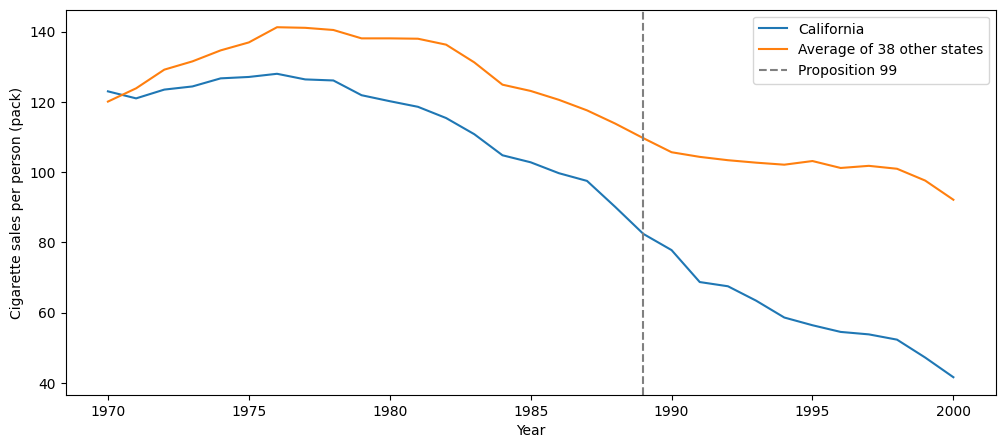

In [82]:
plt.figure(figsize=(12, 5))
plt.plot(calf, label="California")
plt.plot(others, label="Average of 38 other states")
plt.axvline(1989, color="gray", linestyle="--", label="Proposition 99")
plt.xlabel("Year")
plt.ylabel("Cigarette sales per person (pack)")
plt.legend()
plt.show()

California vs. the average of the other 38 states.

We compare California's per capita cigarette sales with the average of the other 38 states (1989 = Proposition 99).

- After 1989: Sales in California drop sharply; while there is also a decline in the other states, it is considerably weaker. This indicates that a general downward trend exists independently of the tax, and it would be incorrect to attribute the entirety of California's decline solely to the tax policy.
- Prior to the tax: The two curves are not parallel. In the mid-1970s, sales in other states increase while California remains stagnant, and after 1980, California declines at a faster rate. The distance between them was already widening even before 1989.

-------------------------------------------------------------------------------------------------------------------------------------
Kaliforniya vs digər 38 ştatın ortalaması.

Kaliforniyanın adambaşına siqaret satışını digər 38 ştatın ortalaması ilə müqayisə edirik (1989 = Proposition 99).

- 1989-dan sonra Kaliforniyada satış kəskin düşür, digər ştatlarda da düşüş var, amma xeyli zəifdir. Yəni ümumi aşağı trend vergidən asılı olmayaraq mövcuddur və Kaliforniyanın bütün düşüşünü vergiyə aid etmək doğru olmaz.
- Vergidən əvvəl iki əyri paralel deyil. 1970-ci illərin ortalarında digərləri artır, Kaliforniya yerində qalır, 1980-dən sonra Kaliforniya daha sürətli düşür. Aralarındakı məsafə 1989-dan əvvəl də artır.

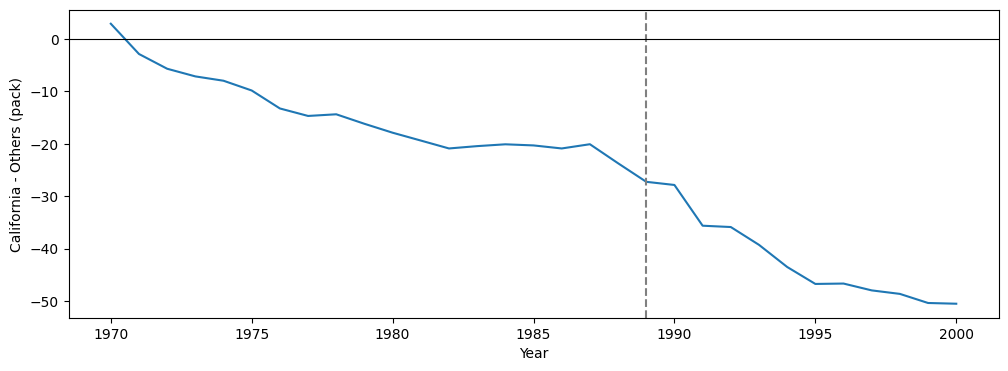

In [83]:
gap = calf - others

plt.figure(figsize=(12, 4))
plt.plot(gap)
plt.axvline(1989, color="gray", linestyle="--")
plt.axhline(0, color="black", linewidth=0.8)
plt.xlabel("Year")
plt.ylabel("California - Others (pack)")
plt.show()

California minus the average of other states.

This was implemented to verify whether the two groups moved in parallel prior to the tax.

- Between 1970 and 1982: The difference drops from approximately +3 to −21, meaning California systematically diverges from the other states. During this period, the parallel trends assumption is violated.
- Between 1982 and 1987: The difference remains stable around −20, indicating that the trends are roughly parallel in this specific section.
- After 1989: The gap widens significantly, moving from approximately −27 down to −50.

-------------------------------------------------------------------------------------------------------------------------------------
Kaliforniya − digər ştatların ortalaması.

Vergidən əvvəl iki qrupun paralel hərəkət edib-etmədiyini yoxlamaq üçün tətbiq edilmişdir.

- 1970-1982 arası fərq təxminən +3-dən −21-ə düşür, yəni Kaliforniya digərlərindən sistemli şəkildə ayrılır. Bu dövrdə paralel trend fərziyyəsi pozulur.
- 1982-1987 arası fərq təxminən −20 ətrafında sabit qalır, bu hissədə trendlər təxminən paraleldir.
- 1989-dan sonra fərq təxminən −27-dən −50-yə qədər genişlənir.

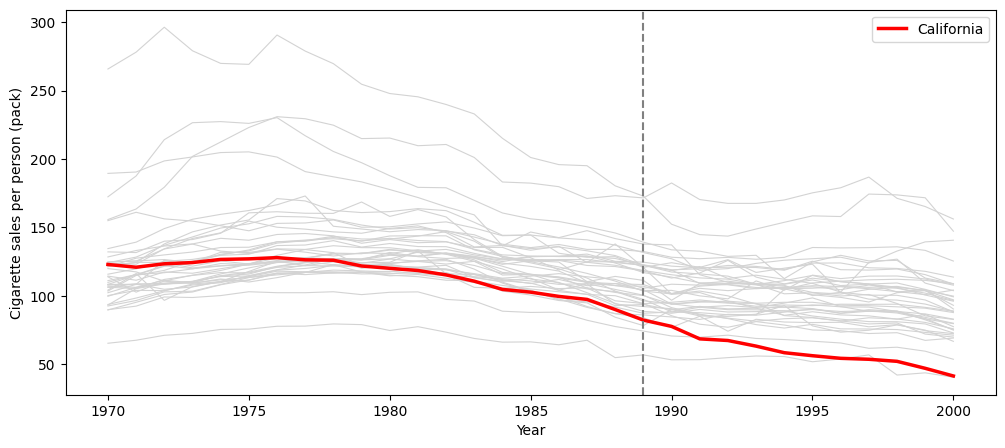

In [84]:
plt.figure(figsize=(12, 5))
for s in df["state"].unique():
    if s != "California":
        d = df[df["state"] == s]
        plt.plot(d["year"], d["cigsale"], color="lightgray", linewidth=0.8)

d = df[df["state"] == "California"]
plt.plot(d["year"], d["cigsale"], color="red", linewidth=2.5, label="California")
plt.axvline(1989, color="gray", linestyle="--")
plt.xlabel("Year")
plt.ylabel("Cigarette sales per person (pack)")
plt.legend()
plt.show()

California Among Other States: This was implemented to observe where California stands in comparison to the individual trajectories of the other 38 states.

- Prior to 1989: California lies right inside the dense cluster of other states (at approximately 100–140 packs). This means that there are several states with trajectories similar to its own.
- Variations Among States: There are massive disparities among the other states, with sales in some reaching as high as 200–300 packs. These high-performing states pull the simple average upward, making it a weak point of comparison for California.
- After 1989: California decouples downward from the cluster and drops to a level close to the lowest trajectories by the year 2000.

-----------------------------------------------------------------------------------------------------------------------------------------------------------
Kaliforniya digər ştatlar arasında: Kaliforniyanın digər 38 ştatın fərdi trayektoriyaları ilə müqayisədə harada yerləşdiyini görmək üçün tətbiq olunub.

- 1989-dan əvvəl Kaliforniya digər ştatların sıx dəstəsinin içində yerləşir (təxminən 100-140 paket). Yəni ona oxşar trayektoriyası olan bir neçə ştat var.
- Digər ştatlar arasında böyük fərqlər var, bəzilərində satış 200-300 paketə çatır. Bu ştatlar sadə ortalamanı yuxarı çəkir və onu Kaliforniya üçün zəif müqayisə nöqtəsinə çevirir.
- 1989-dan sonra Kaliforniya dəstədən aşağıya ayrılır və 2000-ə qədər ən aşağı trayektoriyalara yaxın səviyyəyə düşür.

In [85]:
pre_ca  = calf[calf.index < 1989].mean()
post_ca = calf[calf.index >= 1989].mean()
pre_ot  = others[others.index < 1989].mean()
post_ot = others[others.index >= 1989].mean()

print("California change:", round(post_ca - pre_ca, 1))
print("Others change:", round(post_ot - pre_ot, 1))
print("Difference (rough DiD):", round((post_ca - pre_ca) - (post_ot - pre_ot), 1))

California change: -55.9
Others change: -28.5
Difference (rough DiD): -27.3


The rough DiD estimate is −27.3 packs per capita (based on the difference in average pre/post changes). This is a descriptive estimate, not a reliable causal estimate by itself.

The DiD interpretation depends on the parallel-trends assumption. The pre-intervention gap between California and the other states was already changing substantially (approximately +3 to −27 in the plotted comparison), which raises serious concerns about that assumption. Therefore, −27.3 should not be interpreted as the amount caused by the tax and should not be used as the final causal estimate.

-------------------------------------------------------------------------------------------------------------------------------------
Təxmini DiD nəticəsi adambaşına −27.3 paketdir (müdaxilədən əvvəlki və sonrakı orta dəyişikliklərin fərqi). Bu, təsviri təxmindir, təkbaşına etibarlı səbəb-nəticə təsiri deyil.

DiD nəticəsinin səbəb-nəticə kimi şərhi paralel trend fərziyyəsindən asılıdır. Qrafikdə Kaliforniya ilə digər ştatlar arasındakı fərq müdaxilədən əvvəl də xeyli dəyişirdi (təxminən +3-dən −27-yə). Bu, həmin fərziyyə ilə bağlı ciddi şübhə yaradır. Buna görə −27.3 rəqəmini verginin yaratdığı təsir kimi şərh etmək və yekun səbəb-nəticə təxmini kimi istifadə etmək olmaz.

### Method Selection

In [86]:
n_control = df[df["state"] != "California"]["state"].nunique()
pre_years = df[df["year"] < 1989]["year"].nunique()
post_years = df[df["year"] >= 1989]["year"].nunique()

print("Number of states treated: 1")
print("Control state count:", n_control)
print("Number of pre-period years:", pre_years)
print("Number of post-period years:", post_years)

Number of states treated: 1
Control state count: 38
Number of pre-period years: 19
Number of post-period years: 12


- Problem and Core Question:
It is a reality that cigarette sales in California declined after the tobacco tax was implemented. However, there is a crucial nuance here: sales were already on a downward trajectory even prior to the tax. In this situation, the core question arises: How much of this observed decline is due specifically to the tax, and how much is simply part of the natural downward trend that would have occurred anyway?

- Methodology: "What would have happened without the tax?"
To find an answer to this question, we must compare the actual sales figures with a counterfactual scenario: "How would sales have changed if the tax had not been implemented?" Naturally, a tax-free scenario does not exist in reality, so we must estimate it.
We have a perfect opportunity to verify the reliability of our chosen estimation method: the pre-intervention period (1970–1988). During these years, the tax was not yet in place, and the actual sales figures are known. If our chosen method can accurately replicate the real California during this period, we can then trust the projections it provides for the post-tax period.

- Comparison of Alternative Methods:
1. DiD (Difference-in-Differences):
This method compares California with the simple average of the other states. However, looking at the differences, we can see that the distance between California and the other states did not remain constant during the pre-intervention period; their trends moved in different directions. Because the parallel trends assumption is violated, based on the visual check.
2. Synthetic Control Method (SCM):
This method does not rely on a simple average of the other states. Instead, it assigns specific weights (percentages) to the other states to construct an artificial "Synthetic California" that replicates California's trajectory to the maximum extent possible. Since California's values lie within the range of the other states' trajectories, constructing such an ideal combination is appears feasible.

- Final Decision and Risk:
Chosen Method: Synthetic Control.
However, the extent to which this method fits the pre-intervention period (pre-period fit) is not yet clear.

-----------------------------------------------------------------------------------------------------------------------------------------------------------
- Problem və Əsas Sual:
Kaliforniyada tütün vergisi tətbiq olunduqdan sonra siqaret satışlarının azaldığı bir reallıqdır. Lakin burada mühüm bir məqam var: satışlar onsuz da vergidən əvvəl də aşağı düşməyə doğru gedirdi. Bu vəziyyətdə qarşıya əsas sual çıxır: Baş verən bu azalmanın nə qədəri məhz verginin təsiridir, nə qədəri isə zatən baş verəcək təbii azalma trendidir?

- Metodologiya: "Bəs vergi olmasaydı nə olardı?"
Bu suala cavab tapmaq üçün biz real satış göstəricilərini, "vergi tətbiq olunmasaydı satışlar necə dəyişərdi?" ssenarisi (əks-faktlar) ilə müqayisə etməliyik. Təbii ki, vergisiz ssenari real həyatda mövcud deyil, ona görə də biz onu təxmin etməliyik.
Seçəcəyimiz təxmin metodunun nə qədər etibarlı olduğunu yoxlamaq üçün əlimizdə mükəmməl bir fürsət var: Vergidən əvvəlki dövr (1970–1988). Bu illərdə hələ vergi yox idi və real satış rəqəmləri məlumdur. Əgər seçdiyimiz metod bu dövrdə real Kaliforniyanı dəqiqliklə təkrarlaya bilsə, deməli, onun vergidən sonrakı dövr üçün verdiyi proqnozlara da güvənə bilərik.

- Alternativ Metodların Müqayisəsi:
1. DiD (Difference-in-Differences / Fərqlərin Fərqi):
Bu metod Kaliforniyanı digər ştatların sadə ortalaması ilə müqayisə edir. Lakin fərq qrafikinə baxdıqda görürük ki, vergidən əvvəlki dövrdə Kaliforniya ilə digər ştatlar arasındakı məsafə sabit qalmayıb, trendlər fərqli istiqamətlərdə hərəkət edib. Paralel trend şərti vizual yoxlamaya əsaslanır.
2. Synthetic Control (Sintetik Nəzarət Metodu):
Bu metod digər ştatların sadə ortalamasını götürmür. Əvəzində, digər ştatlara xüsusi çəkilər (faizlər) təyin edərək Kaliforniyanın trayektoriyasını maksimum dərəcədə kopyalayan süni bir "Sintetik Kaliforniya" yaradır. Kaliforniyanın göstəriciləri digər ştatların göstəriciləri arasında yerləşdiyindən, belə bir ideal kombinasiyanı qurmaq mümkün görünür.

- Yekun Qərar və Risk:
Seçilən Metod: Synthetic Control (Sintetik Nəzarət).

Lakin, bu metodun vergidən əvvəlki dövrə (pre-period) nə qədər uyğunlaşdığı hələ aydın deyil. 

### Synthetic Control

In [87]:
pivot = df.pivot(index="year", columns="state", values="cigsale")
donors = pivot.drop(columns="California")

inside = (calf >= donors.min(axis=1)) & (calf <= donors.max(axis=1))
print(inside[pivot.index < 1989].mean())

1.0


We check whether California's outcome falls within the donor states' yearly minimum–maximum range during the pre-intervention period.
The value 1 means that California was within this range in every year from 1970 to 1988. This is a useful feasibility check, but it does not prove that a single set of non-negative weights will reproduce California closely over the whole pre-period. The actual pre-period fit must be assessed using the optimized synthetic series and its RMSE.

-------------------------------------------------------------------------------------------------------------------------------------
Vergi müdaxilələrindən əvvəlki dövrdə Kaliforniyanın nəticə göstəricisinin donor ştatların illik minimum–maksimum aralığında olub-olmadığını yoxlayırıq.
Nəticənin 1 olması Kaliforniyanın 1970–1988-ci illərin hər birində bu aralıqda olduğunu göstərir. Bu faydalı ilkin yoxlamadır, lakin eyni qeyri-mənfi çəkilər dəstinin bütün dövr ərzində Kaliforniyanı dəqiq təkrarlayacağını sübut etmir. Faktiki uyğunluq optimallaşdırılmış sintetik sıra və onun RMSE göstəricisi ilə qiymətləndirilməlidir.

In [88]:
import numpy as np
from scipy.optimize import minimize

In [89]:
pre = pivot[pivot.index < 1989]
X = pre.drop(columns="California").values
y = pre["California"].values                

n = X.shape[1]
res = minimize(lambda w: ((y - X @ w) ** 2).sum(), np.ones(n) / n, bounds=[(0, 1)] * n,
constraints={"type": "eq", "fun": lambda w: w.sum() - 1}, method="SLSQP")

weights = pd.Series(res.x, index=donors.columns)
print(weights[weights > 0.01].round(3))

synth = donors @ weights

state
Alabama           0.026
Arkansas          0.026
Colorado          0.026
Connecticut       0.026
Delaware          0.026
Georgia           0.026
Idaho             0.026
Illinois          0.026
Indiana           0.026
Iowa              0.026
Kansas            0.026
Kentucky          0.026
Louisiana         0.026
Maine             0.026
Minnesota         0.026
Mississippi       0.026
Missouri          0.026
Montana           0.026
Nebraska          0.026
Nevada            0.026
New Hampshire     0.026
New Mexico        0.026
North Carolina    0.026
North Dakota      0.026
Ohio              0.026
Oklahoma          0.026
Pennsylvania      0.026
Rhode Island      0.026
South Carolina    0.026
South Dakota      0.026
Tennessee         0.026
Texas             0.026
Utah              0.026
Vermont           0.026
Virginia          0.026
West Virginia     0.026
Wisconsin         0.026
Wyoming           0.026
dtype: float64


Upon closer inspection, instead of assigning unique weights to different states, the algorithm distributed completely equal weights (0.026, i.e., \(1/38\)) to each of the 38 donor states in the model.

This result mathematically indicates that the optimization algorithm (SLSQP) failed to achieve proper convergence and got stuck at the initial guess point. If we proceed this way, the resulting 'Synthetic California' will not be a distinct weighted model; rather, it will be identical to the simple average of other states (the classic DiD baseline) that we rejected in the previous stage.

The "scipy.optimize.minimize" function can occasionally fail to locate the global minimum when dealing with large matrices and rigid constraints. To resolve this technical issue and ensure the model calculates the true weights, we must either stabilize the objective function or adjust the initial guess.

-------------------------------------------------------------------------------------------------------------------------------------
Diqqət yetirsək, alqoritm fərqli ştatlara fərqli çəkilər təyin etmək əvəzinə, modeldəki 38 donor ştatın hər birinə tamamilə bərabər çəki (0.026, yəni \(1/38\)) paylamışdır.

Bu nəticə riyazi olaraq optimallaşdırma alqoritminin (SLSQP) doğru yaxınlaşma (convergence) edə bilmədiyini və ilkin təxmin nöqtəsində ilişib qaldığını göstərir. Bu şəkildə davam etsək, əldə edəcəyimiz "Sintetik Kaliforniya" fərqli çəkili model yox, elə əvvəlki mərhələdə rədd etdiyimiz "digər ştatların sadə ortalaması" (klassik DiD bazası) ilə eyni olacaq.

"scipy.optimize.minimize" funksiyası bəzən böyük matrislərdə və sərt məhdudiyyətlər (constraints) altında qlobal minimumu tapa bilmir. Bu texniki problemi aradan qaldırmaq və modelin həqiqi çəkiləri hesablamasını təmin etmək üçün Məqsəd Funksiyasını bir qədər stabilləşdirməli və ya ilkin təxmini dəyişməliyik.

In [90]:
pre = pivot[pivot.index < 1989]
X = pre.drop(columns="California").values
y = pre["California"].values   

n = X.shape[1]

def objective(w):
    return (((y - X @ w) / 1000) ** 2).sum()
res = minimize(objective, np.ones(n) / n, bounds=[(0, 1)] * n,constraints={"type": "eq", "fun": lambda w: w.sum() - 1},
method="SLSQP", options={"maxiter": 1000, "ftol": 1e-10})

weights = pd.Series(res.x, index=donors.columns)
print("--- NEW WEIGHTS ---")
print(weights[weights > 0.01].round(3))

synth = donors @ weights

--- NEW WEIGHTS ---
state
Colorado         0.036
Connecticut      0.106
Montana          0.204
Nevada           0.202
New Hampshire    0.048
Utah             0.404
dtype: float64


To ensure the algorithm (SLSQP) executes stably and without error, the objective function has been scaled down. Constraints were applied to ensure that the state weights are non-negative and sum up to exactly 1 (100%).

As a result, from the 38 donor states, the model selected 6 specific states that best fit California's historical trend (with Utah having the highest weight at 40.4%) and set the weights of the remaining states to zero.

Using the calculated weights, the 'Synthetic California' time series was constructed. This variable provides us with the counterfactual scenario, answering the question: 'What would cigarette sales in California have looked like if the tax had not been implemented?'

-------------------------------------------------------------------------------------------------------------------------------------
SLSQP alqoritminin xəta vermədən və stabil işləməsi üçün optimizasiya (hədəf) funksiyası miqyaslandırılmışdır (kiçildilmişdir). Ştat çəkilərinin mənfi olmaması və cəminin tam 1 (100%) olması məhdudiyyəti tətbiq edilib.

Nəticə olaraq, model 38 donor ştat arasından Kaliforniyanın keçmiş trendinə ən uyğun gələn 6 spesifik ştatı (ən yüksək pay %40.4 ilə Utah olmaqla) seçib, digər ştatların payını sıfırlayıb.

Tapılan çəkilərlə "Sintetik Kaliforniya" zaman sırası formalaşdırılıb. Bu dəyişən bizə "Vergi tətbiq olunmasaydı, Kaliforniyada siqaret satışı necə olardı?" ssenarisini (əks-faktı) təqdim edir.

In [91]:
# Pre-period RMSE Fit Test
pre_mask = pivot.index < 1989
rmse_pre = np.sqrt(((calf[pre_mask] - synth[pre_mask]) ** 2).mean())

print("Pre-period RMSE:", round(rmse_pre, 2), "packs")
print("Total weights:", round(weights.sum(), 3))
print("Optimizer successful:", res.success)

Pre-period RMSE: 1.66 packs
Total weights: 1.0
Optimizer successful: True


Model Fit and Optimization Test - Following the optimization process, validation tests were conducted to evaluate model performance:
- Pre-period RMSE (1.66 packs): The Root Mean Squared Error between the actual California data and "Synthetic California" prior to the 1989 tax reform is 1.66 packs. This low error confirms that the model accurately replicates the historical trend.
- Total weights (1.0): The sum of the assigned state weights is exactly 1.0 (100%), demonstrating that the constraint was successfully met.
- Optimizer successful (True): The SLSQP algorithm successfully converged, indicating that a valid optimal solution was found.

-------------------------------------------------------------------------------------------------------------------------------------
Modelin Uyğunluq və Optimizasiya Testi - Optimizasiya prosesindən sonra modelin keyfiyyətini və doğruluğunu yoxlamaq üçün testlər aparılmışdır:
- Pre-period RMSE (1.66 packs): Vergi islahatından əvvəlki dövrdə (1989-cu ilə qədər) həqiqi Kaliforniya ilə "Sintetik Kaliforniya" arasındakı orta kvadratik xəta cəmi 1.66 qutu təşkil edir. Bu aşağı xəta modelin keçmiş trendi yüksək dəqiqliklə təqlid etdiyini göstərir.
- Total weights (1.0): Ştatlara verilən çəkilərin cəmi gözlənildiyi kimi tam 1-ə (100%) bərabərdir, yəni qoyulan məhdudiyyət tam ödənilib.
- Optimizer successful (True): SLSQP alqoritmi optimizasiya prosesini uğurla tamamlamış və optimal həlli tapmışdır.

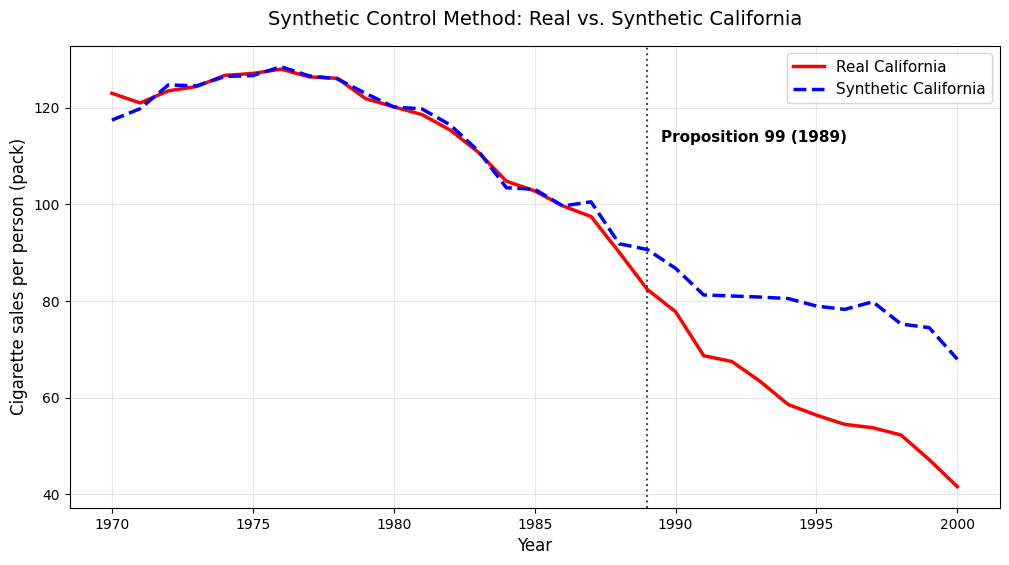

In [92]:
calf = pivot["California"]

plt.figure(figsize=(12, 6))

plt.plot(pivot.index, calf, color="red", linewidth=2.5, label="Real California")
plt.plot(pivot.index, synth, color="blue", linestyle="--", linewidth=2.5, label="Synthetic California")

plt.axvline(1989, color="black", linestyle=":", alpha=0.7)
plt.text(1989.5, max(calf)-15, "Proposition 99 (1989)", color="black", fontsize=11, fontweight="bold")

plt.xlabel("Year", fontsize=12)
plt.ylabel("Cigarette sales per person (pack)", fontsize=12)
plt.title("Synthetic Control Method: Real vs. Synthetic California", fontsize=14, pad=15)
plt.legend(fontsize=11)
plt.grid(True, alpha=0.3)

plt.show()

The data was visualized to evaluate how accurately the "Synthetic California" model replicates the pre-intervention period and to observe the true impact of the 1989 tobacco tax.

Prior to 1989, the trajectories of the real (red) and synthetic (blue dashed) lines almost completely overlap, demonstrating that the model successfully replicates California's historical trend. Immediately following the implementation of the law in 1989, the gap between the two lines steadily widens.

Importantly, cigarette sales were already on a natural decline before the tax, a trend accurately captured by the synthetic counterfactual line. After 1989, however, real sales fall well below this natural decline. While this substantial gap serves as a strong initial indicator of the tax effect, placebo tests are required to confirm its statistical significance.

-----------------------------------------------------------------------------------------------------------------------------------------------------------
"Sintetik Kaliforniya" modelinin effektivliyini və 1989-cu il tütün vergisinin (Proposition 99) real təsirini qiymətləndirmək üçün vizuallaşdırma aparılmışdır.

1989-cu ilə qədər real (qırmızı) və sintetik (mavi kəsik) xətlərin trayektoriyası demək olar ki, tamamilə üst-üstə düşür. Bu, modelin Kaliforniyanın vergidən əvvəlki təbii trendini uğurla kopyaladığını sübut edir. İslahatın tətbiqindən dərhal sonra isə iki xətt arasındakı fərq (gap) getdikcə böyüyür.

Qrafikdən görünür ki, Kaliforniyada siqaret satışları vergidən əvvəl də təbii bir azalma trendində olub və mavi xətt ("vergi olmasaydı nə olardı" ssenarisi) bu azalmanı qoruyur. Lakin, 1989-cu ildən sonra real satışlar bu təbii azalma gözləntisindən qat-qat kəskin şəkildə aşağı düşür. Bu böyük fərq vergi təsirinin ilkin göstəricisidir, lakin yekun nəticə üçün bu təsir gələcək "placebo" testləri ilə yoxlanılmalıdır.

In [93]:
# Calculation of Final ATT (Causal Estimate)
post_mask = pivot.index >= 1989
effects_post = calf[post_mask] - synth[post_mask]

att = effects_post.mean()
print("ATT (average annual effect, 1989-2000):", round(att, 2), "packs")
print("Effect in 1989:", round(effects_post.iloc[0], 1), "packs")
print("Effect in 2000:", round(effects_post.iloc[-1], 1), "packs")

ATT (average annual effect, 1989-2000): -19.32 packs
Effect in 1989: -8.3 packs
Effect in 2000: -26.4 packs


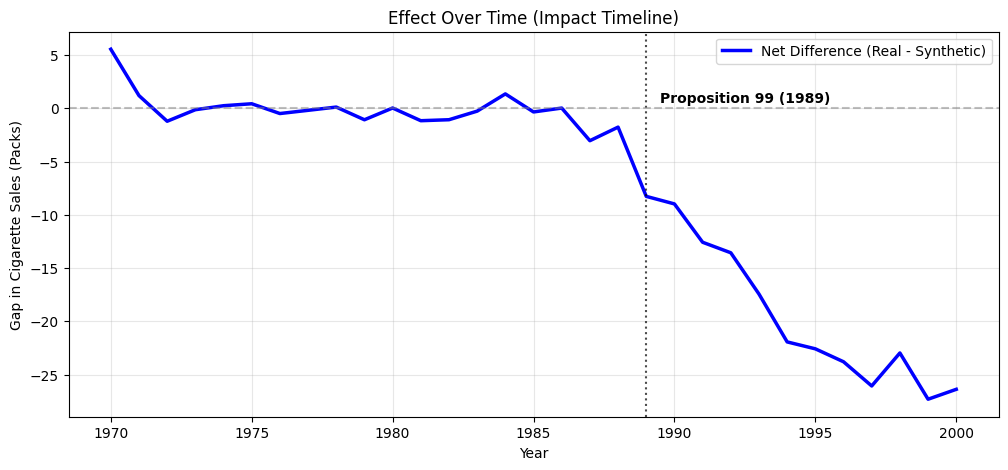

In [94]:
gap_series = calf - synth

plt.figure(figsize=(12, 5))
plt.plot(gap_series.index, gap_series.values, color="blue", linewidth=2.5, label="Net Difference (Real - Synthetic)")
plt.axvline(1989, color="black", linestyle=":", alpha=0.7)
plt.axhline(0, color="gray", linestyle="--", alpha=0.5)

plt.text(1989.5, max(gap_series.values)-5, "Proposition 99 (1989)", color="black", fontsize=10, fontweight="bold")
plt.xlabel("Year")
plt.ylabel("Gap in Cigarette Sales (Packs)")
plt.title("Effect Over Time (Impact Timeline)")
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

The plot shows the yearly gap between real and synthetic California; the ATT (-19.32 packs) is its average over 1989-2000.

- Before 1989 the gap stays close to zero, so the synthetic control tracked California well.
- After 1989 the gap keeps falling, from about -8 in 1989 to about -26 in 2000, i.e. the effect grows gradually and flattens towards the end.
- This is an estimated gap, not a proven tax effect: it assumes no other California-specific change around 1989, and the placebo test (p ≈ 0.08) is suggestive, not significant at 5%.

-----------------------------------------------------------------------------------------------------------------------------------------------------------
Qrafik real və sintetik Kaliforniya arasındakı illik fərqi göstərir; ATT (-19.32 paket) bu fərqin 1989-2000 üzrə ortalamasıdır.

- 1989-dan əvvəl fərq sıfıra yaxındır, yəni sintetik xətt Kaliforniyanı yaxşı izləyib.
- 1989-dan sonra fərq davamlı düşür: 1989-da təxminən -8-dən 2000-də təxminən -26-ya, yəni effekt tədricən artır və sonda sabitləşir.
- Bu, təxmin edilən fərqdir, sübut olunmuş vergi təsiri deyil: 1989 ətrafında Kaliforniyaya xas başqa dəyişikliyin olmadığını fərz edir, placebo testi (p ≈ 0.08) isə təklif edicidir, 5%-də əhəmiyyətli deyil.

### Placebo test

In [95]:
def fit_weights(target, pool):
    X = pool[pre_mask].values
    y = target[pre_mask].values
    n = X.shape[1]
    obj = lambda w: (((y - X @ w) / 1000) ** 2).sum()
    r = minimize(obj, np.ones(n) / n, bounds=[(0, 1)] * n,constraints={"type": "eq", "fun": lambda w: w.sum() - 1},
    method="SLSQP", options={"maxiter": 1000, "ftol": 1e-10})
    return pd.Series(r.x, index=pool.columns)

def rmspe(s, mask):
    return np.sqrt((s[mask] ** 2).mean())

gaps, rows = {}, []
for s in donors.columns:
    pool = donors.drop(columns=s)
    g = donors[s] - pool @ fit_weights(donors[s], pool)
    gaps[s] = g
    rows.append((s, rmspe(g, pre_mask), rmspe(g, post_mask)))

pl = pd.DataFrame(rows, columns=["state", "pre", "post"]).set_index("state")
pl["ratio"] = pl["post"] / pl["pre"]

ca_pre, ca_post = rmspe(gap_series, pre_mask), rmspe(gap_series, post_mask)
ca_ratio = ca_post / ca_pre
p_value = ((pl["ratio"] >= ca_ratio).sum() + 1) / (len(pl) + 1)

print("California post/pre RMSPE ratio:", round(ca_ratio, 1))
print("Placebo p-value:", round(p_value, 3))
print(pl.sort_values("ratio", ascending=False).head(5).round(2))

California post/pre RMSPE ratio: 12.3
Placebo p-value: 0.077
           pre   post  ratio
state                       
Missouri  0.47  10.04  21.58
Virginia  0.83  15.68  18.96
Georgia   1.09   9.90   9.05
Texas     1.92  15.69   8.18
Oklahoma  1.96  15.94   8.12


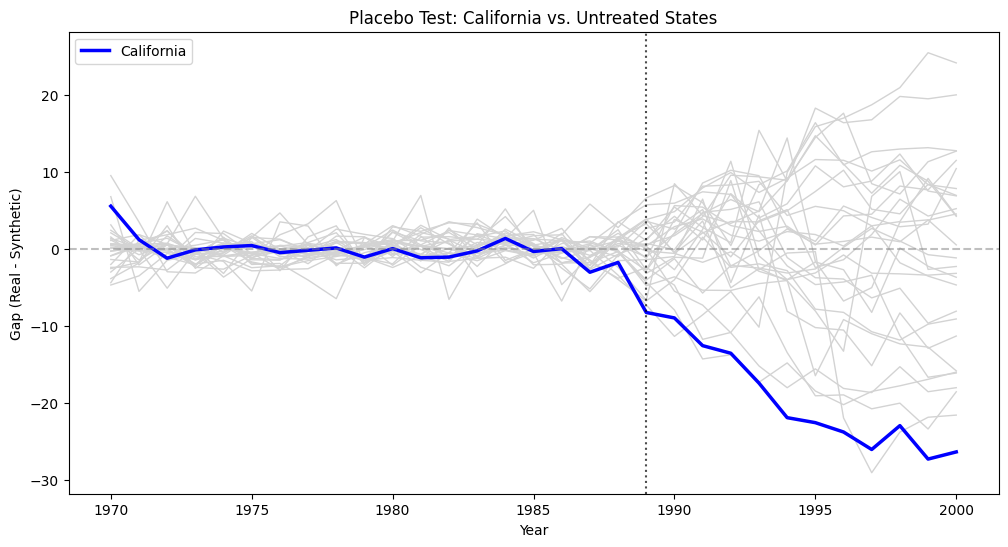

In [96]:
good_fit = pl[pl["pre"] <= 2 * ca_pre].index 

plt.figure(figsize=(12, 6))
for s in good_fit:
    plt.plot(gaps[s].index, gaps[s].values, color="lightgray", linewidth=1)
plt.plot(gap_series.index, gap_series.values, color="blue", linewidth=2.5, label="California")
plt.axvline(1989, color="black", linestyle=":", alpha=0.7)
plt.axhline(0, color="gray", linestyle="--", alpha=0.5)
plt.xlabel("Year")
plt.ylabel("Gap (Real - Synthetic)")
plt.title("Placebo Test: California vs. Untreated States")
plt.legend()
plt.show()

This was implemented to check whether a gap as large as California's could appear by chance. We applied the same synthetic control method to each of the 38 untreated states as if it had been treated in 1989 (no data was changed).

- Calculation result: California's post/pre RMSPE ratio is 12.3, which ranks 3rd among 39 states, behind Missouri (21.6) and Virginia (19.0). The placebo p-value is about 0.08 (3/39).
- Plot result: Before 1989 the placebo gaps stay close to zero, like California's. After 1989 they spread widely (roughly -29 to +25 packs), while California falls to about -26, near the lower edge of this range but not alone.
- Overall: California's gap is among the largest, but not unique, so the effect is suggestive but not statistically significant at the 5% level.

-----------------------------------------------------------------------------------------------------------------------------------------------------------
Kaliforniyanın boşluğu qədər böyük boşluğun təsadüfən yaranıb-yaranmadığını yoxlamaq üçün tətbiq olunub. Eyni synthetic control metodunu 38 nəzarət ştatının hər birinə sanki 1989-da vergi alıblarmış kimi tətbiq etdik (data dəyişdirilməyib).

- Hesablama nəticəsi: Kaliforniyanın post/pre RMSPE nisbəti 12.3-dür və 39 ştat arasında 3-cü yerdədir, Missouri (21.6) və Virginia-dan (19.0) sonra. Placebo p-dəyəri təxminən 0.08-dir (3/39).
- Qrafik nəticəsi: 1989-dan əvvəl placebo boşluqları Kaliforniya kimi sıfıra yaxındır. 1989-dan sonra geniş yayılır (təxminən -29-dan +25 paketə qədər), Kaliforniya isə təxminən -26-ya düşür, bu aralığın aşağı kənarına yaxındır, amma tək deyil.
- Ümumi nəticə: Kaliforniyanın boşluğu ən böyüklər arasındadır, amma unikal deyil, ona görə effekt təklif edicidir, amma 5% səviyyəsində statistik əhəmiyyətli deyil.

## Final Result

- Method: Synthetic Control (6 donor states: Utah, Montana, Nevada, Connecticut, New Hampshire, Colorado), fitted on 1970-1988 only.
- Assumption check: The synthetic control tracks California closely before 1989 (pre-period RMSE = 1.66 packs).
- Estimate (ATT): -19.32 packs per person per year over 1989-2000; the effect grows from about -8 in 1989 to about -26 in 2000.
- Robustness: The placebo test gives p ≈ 0.08 (California ranks 3rd of 39), so the effect is suggestive but not significant at the 5% level.

-----------------------------------------------------------------------------------------------------------------------------------------------------------
- Metod: Synthetic Control (6 yaxın(uyğun) ştat: Utah, Montana, Nevada, Connecticut, New Hampshire, Colorado), yalnız 1970-1988 üzrə qurulub.
- Fərziyyə yoxlaması: Sintetik xətt 1989-dan əvvəl Kaliforniyanı yaxından izləyir (pre-period RMSE = 1.66 paket).
- Qiymətləndirmə (ATT): 1989-2000 üzrə ildə adambaşına -19.32 paket; effekt 1989-da təxminən -8-dən 2000-də təxminən -26-ya qədər artır.
- Dayanıqlıq: Placebo testi p ≈ 0.08 verir (Kaliforniya 39 ştat arasında 3-cüdür), yəni effekt təklif edicidir, amma 5% səviyyəsində əhəmiyyətli deyil.

## Honest Interpretation

**What We Can Say:**
-True Impact (ATT = -19.32): After 1989, California's cigarette sales fell by an average of 19.32 packs per person per year more than its synthetic counterfactual.
- Widening Gap: The impact intensified over time, with the gap between actual and synthetic sales growing from -8 packs in 1989 to -26 packs by 2000.
- Strong Historical Fit (Pre-RMSE = 1.66): The synthetic control tracked California closely during the 19-year pre-period, validating the mathematical credibility of the counterfactual.

**What We Cannot Say:**
- Exclusive Causation: We cannot definitively assert that the tax alone caused this gap, as the model relies on the assumption that no other California-specific changes occurred around 1989.
- Strict Statistical Proof: The effect is not statistically proven beyond doubt; the placebo test (p ≈ 0.08) is not significant at the conventional 5% level.

**Threats to the Estimation:**
1. Confounding Local Policies: Other state-specific interventions around 1989 (anti-smoking campaigns, local bans) might be driving the decline but are wrongly attributed entirely to the tax.
2. Spillover Effects: Cross-border purchases by California smokers in neighboring donor states could cross-contaminate the control group data.
3. Unobserved Shocks: The method cannot detect sudden, unobserved socioeconomic shocks that occur over time.
4. Outcome-Only Matching: The synthetic control was constructed solely using past cigarette sales (outcome), omitting key economic and demographic predictors.
5. Overfitting Risks: Achieving a tight in-sample fit using 38 donor states over a 19-year pre-period can partly reflect overfitting.
6. Placebo Anomalies: Two untreated states (Missouri and Virginia) show larger post/pre RMSPE ratios than California, highlighting the presence of baseline statistical noise.

We can attribute a certain portion of the decline to the implementation of the tax. However, since there are other potential confounding factors, we cannot link the decline solely to the tax itself.

-----------------------------------------------------------------------------------------------------------------------------------------------------------
**Nəyi deyə bilərik:**
- Real Təsir (ATT = -19.32): 1989-cu ildən sonra Kaliforniyada siqaret satışları, vergi olmasaydı baş verəcək ssenaridən (sintetik kontrafaktualdan) ildə adambaşına orta hesabla 19.32 qutu daha çox azalıb.
- Zamanla Böyüyən Fərq: Verginin təsiri ildən-ilə güclənib; real satışlar ilə sintetik xətt arasındakı fərq 1989-cu ildə -8 qutu ikən, 2000-ci ildə -26 qutuya yüksəlib.
- Güclü Keçmiş Uyğunluq (Pre-RMSE = 1.66): Vergidən əvvəlki 19 ildə sintetik xətt Kaliforniyanı addım-addım izləyib, bu da kontrafaktual ssenarinin riyazi etibarlılığını təsdiqləyir.

**Nəyi deyə bilmərik:**
- Mütləq Səbəb-Nəticə: Bu azalmanın sırf və yalnız tütün vergisindən qaynaqlandığını iddia edə bilmərik, çünki model 1989 ətrafında Kaliforniyaya xas başqa heç nəyin dəyişmədiyi fərziyyəsinə söykənir.
- Sərt Statistik Sübut: Effektin statistik olaraq tam sübut olunduğunu deyə bilmərik; placebo testi (p ≈ 0.08) ekonometrikada qəbul olunmuş 5% əhəmiyyətlilik limitindən yüksəkdir.

**Qiymətləndirməyə Təhdidlər (Potential Threats):**
1. Paralel Kampaniyalar: 1989 ətrafındakı digər antitütün maarifləndirmələri və regional qadağalar səhvən birbaşa vergiyə aid edilə bilər.
2. Sızma Effekti (Spillover): Kaliforniyadakı alıcıların vergidən qaçmaq üçün qonşu ştatlardan siqaret alması donor ştatların datasını çirkləndirə bilər.
3. Gizli Şoklar: Zaman daxilində baş verən və verilənlərdə əks olunmayan qəfil sosial-iqtisadi şoklar bu metodla aşkar edilə bilmir.
4. Prediktor Çatışmazlığı: Sintetik Kaliforniya modeli demoqrafik və iqtisadi göstəricilər (gəlir, yaş və s.) buraxılaraq yalnız keçmiş satış rəqəmləri (outcome) üzərindən qurulub.
5. Həddindən Artıq Uyğunlaşma (Overfitting): 19 illik pre-period üçün 38 donor ştatın istifadəsi keçmiş uyğunluğu artırsa da, modelin proqnoz gücünü qismən zəiflədə bilər.
6. Placebo Səs-küyü: İki nəzarət ştatında (Missouri və Virginia) post/pre xəta nisbətinin Kaliforniyadan böyük olması bazadakı statistik səs-küyün yüksək olduğunu göstərir.

Azalmanın müəyyən hissəsini vergi tətbiqinin təsiri ilə izah edə bilərik. Lakin mümkün ola biləcək digər təsirlər də olduğundan azalmanı sırf vergi ilə əlaqələndirə bilmərik.